In [112]:
import os
import re
from typing import List, Union
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from ccxt.okx import okx

# https://github.com/ranaroussi/quantstats
%matplotlib inline
import quantstats as qs

from siglab_py.util.market_data_util import instantiate_exchange, fetch_candles

TIMEZONE : str = "Asia/Hong_Kong"
ECONOMIC_CALENDAR_FILE = r"economic_calanedar_archive.csv"

TICKER : str = "SOL/USDT:USDT"
BASE_TICKER : str = "SOL"
CANDLES_CACHE_DIR : str = './cache'
REQUIRED_TA : List[str] = [ 'close', 'atr', 'adx' ]
RELOAD_CANDLES : bool = False # You dont want to refresh candles everytime you reload Equity Curve with diff filtering?
RELOAD_DIRECT_FROM_SRC : bool = True # Reload direcly from source instead of relading from disk cache
SRC_EXCHANGE_NAME : str = "okx"
RELOAD_CANDLE_INTERVAL : str = '1h' # For RELOAD_DIRECT_FROM_SRC==True only. Don't do 15m here, takes way too long. Try '1d', or '1h' only.

SLIPPAGE_COST_BPS = 0 # estimation for trade friction besides fees. This is on per trade, round trip basis. Note, subtracting on after-the-fact basis not very accurate. More accurate approach is for backtest_core to adjust entry price.
MAXPAIN_CUTOFF_BPS = 50
RISK_FREE_RATE = 0.035

ACC_EQUITY = 100000

RETURN_RESAMPLE_FREQ = "D" # D for daily, W for weekly
RETURN_CALC_METHODOLOGY = "log" # log or simple

In [113]:
trade_files = [
    'backtest_macd_crosses_strategy_15m_tc_20250101_ETHUSDTUSDT_0.csv',
]

trade_files = [
    'backtest_macd_crosses_strategy_15m_tc_20230101_ETHUSDTUSDT_1.csv',
    'backtest_macd_crosses_strategy_15m_tc_20240101_ETHUSDTUSDT_1.csv',
    'backtest_macd_crosses_strategy_15m_tc_20250101_ETHUSDTUSDT_1.csv',
    'backtest_macd_crosses_strategy_15m_tc_20260101_ETHUSDTUSDT_1.csv'
]

In [114]:
def candles_ta_files_2_dataframe(
    candles_ta_files : List[str]
):
    _candles_ta_files = []
    for candles_ta_file in candles_ta_files:
        pd_candles_ta = pd.read_csv(candles_ta_file)

        if not all(col in pd_candles_ta.columns for col in REQUIRED_TA):
            continue

        _candles_ta_files.append(pd_candles_ta)
    pd_candles_ta = pd.concat(_candles_ta_files, ignore_index=True)
    pd_candles_ta.drop_duplicates(subset='timestamp_ms', inplace=True)
    pd_candles_ta.drop(pd_candles_ta.columns[pd_candles_ta.columns.str.contains('unnamed',case = False)],axis = 1, inplace = True)
    pd_candles_ta.sort_values(by='timestamp_ms', ascending=True, inplace=True)
    return pd_candles_ta

def trade_files_2_dataframe(
    trade_files : List[str]
) -> pd.DataFrame:
    _trade_files = []
    for trade_file in trade_files:
        pd_flattened_trades = pd.read_csv(trade_file)
        pd_flattened_trades['entry_timestamp_ms'] = pd_flattened_trades['timestamp_ms'].shift(1) # Assume no overlapping trades
        pd_flattened_trades['entry_datetime'] = pd.to_datetime(pd_flattened_trades['entry_timestamp_ms'], unit='ms', utc=True).dt.tz_convert(TIMEZONE)
        pd_flattened_trades['entry_date'] = pd_flattened_trades['entry_datetime'].dt.date
        pd_flattened_trades['entry_dayofweek'] = pd_flattened_trades['entry_datetime'].dt.dayofweek
        pd_flattened_trades = pd_flattened_trades[(pd_flattened_trades['reason'] != 'entry') & (pd_flattened_trades['reason'] != 'HC')]
        _trade_files.append(pd_flattened_trades)

    pd_flattened_trades = pd.concat(_trade_files, ignore_index=True)
    pd_flattened_trades.drop(pd_flattened_trades.columns[pd_flattened_trades.columns.str.contains('unnamed',case = False)],axis = 1, inplace = True)

    # SLIPPAGE_COST_BPS
    pd_flattened_trades['slippage_cost'] = pd_flattened_trades['order_notional'] * SLIPPAGE_COST_BPS/10000
    pd_flattened_trades['trade_pnl_less_comm_and_slippage'] = pd_flattened_trades['trade_pnl_less_comm'] - pd_flattened_trades['slippage_cost']
    
    return pd_flattened_trades

def filter_trades(pd_flattened_trades : pd.DataFrame) -> pd.DataFrame:
    # pd_flattened_trades = pd_flattened_trades[pd_flattened_trades.num_impacting_economic_calendars==0]
    # pd_flattened_trades = pd_flattened_trades[~pd_flattened_trades.entry_dayofweek.isin([0,3])]
    # pd_flattened_trades = pd_flattened_trades[(pd_flattened_trades.entry_hour>=7)]
    # pd_flattened_trades = pd_flattened_trades[(pd_flattened_trades.entry_hour>=3) & (pd_flattened_trades.entry_hour<=18)]
    # pd_flattened_trades = pd_flattened_trades[~pd_flattened_trades.entry_hour.isin([8,9,10])] # After APAC open momentum wanes
    # pd_flattened_trades = pd_flattened_trades[~pd_flattened_trades.entry_hour.isin([18,19,20,21])] # Before US cash open
    return pd_flattened_trades

def calc_return(
        pd_flattened_trades : pd.DataFrame,
        return_calc_methodology : str = 'log'
    ):
    # pd_flattened_trades = pd_flattened_trades.loc[:,['trade_datetime', 'trade_year', 'trade_month', 'trade_day', 'trade_pnl_less_comm']]
    # pd_flattened_trades = pd_flattened_trades[pd_flattened_trades.timestamp_ms!=1740931200000]
    pd_flattened_trades.sort_values(by=['trade_datetime'], ascending=[True])
    pd_flattened_trades['trade_datetime'] = pd.to_datetime(pd_flattened_trades['trade_datetime'])
    pd_flattened_trades['total_equity'] = pd_flattened_trades['trade_pnl_less_comm_and_slippage'].cumsum() # SLIPPAGE_COST_BPS
    pd_flattened_trades['total_equity'] = pd_flattened_trades['total_equity'] + ACC_EQUITY

    if return_calc_methodology=='simple':
        pd_flattened_trades['interval_return'] = (pd_flattened_trades['total_equity'] / pd_flattened_trades['total_equity'].shift(1)) - 1 # Simple return
        pd_flattened_trades['interval_return'].fillna(0, inplace=True)
        pd_flattened_trades['cumulative_interval_return'] = (1 + pd_flattened_trades['interval_return']).cumprod() # cumprod is multiplicative, for Simple return

    elif return_calc_methodology=='log':
        pd_flattened_trades['interval_return'] = np.log(pd_flattened_trades['total_equity'] / pd_flattened_trades['total_equity'].shift(1)) # Log return
        pd_flattened_trades['interval_return'].fillna(0, inplace=True)
        pd_flattened_trades['cumulative_interval_return'] = pd_flattened_trades['interval_return'].cumsum() # cumsum is additive, for Log return

        # Check against final total_equity: This assumes you trades opens bigger and bigger (re-invest gains, assuming it's making money)
        pd_flattened_trades['growth_factor'] = np.exp(pd_flattened_trades['cumulative_interval_return'])
        pd_flattened_trades['final_equity_check'] = ACC_EQUITY * pd_flattened_trades['growth_factor'] # Will be different from final 'total_equity' if your strategy don't re-invest gains, under or over leverage!

    pd_flattened_trades['trade_datetime'] = pd.to_datetime(pd_flattened_trades['trade_datetime'])
    pd_flattened_trades.set_index('trade_datetime', inplace=True)

Load trade files

In [115]:
pd_flattened_trades = trade_files_2_dataframe(trade_files=trade_files)
pd_flattened_trades = filter_trades(pd_flattened_trades=pd_flattened_trades)
calc_return(pd_flattened_trades=pd_flattened_trades, return_calc_methodology=RETURN_CALC_METHODOLOGY)
min_timestamp_ms = pd_flattened_trades['timestamp_ms'].min()
max_timestamp_ms = pd_flattened_trades['timestamp_ms'].max()

C:\Users\norma\AppData\Local\Temp\ipykernel_18828\991069945.py:67: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  pd_flattened_trades['interval_return'].fillna(0, inplace=True)


Load economic calendar

In [116]:
pd_economic_calendars = pd.read_csv(ECONOMIC_CALENDAR_FILE)
pd_economic_calendars.drop(pd_economic_calendars.columns[pd_economic_calendars.columns.str.contains('unnamed',case = False)],axis = 1, inplace = True)
pd_economic_calendars['datetime'] = pd.to_datetime(pd_economic_calendars['calendar_item_timestamp_ms'], unit='ms', utc=True).dt.tz_convert(TIMEZONE)
pd_economic_calendars['date'] = pd_economic_calendars['datetime'].dt.date
pd_economic_calendars = pd_economic_calendars[(pd_economic_calendars.importance==3) & (~pd_economic_calendars.event_code.isnull())]
economic_calendar_dates = pd_economic_calendars['date'].tolist()
economic_calendar_ts = pd_economic_calendars['calendar_item_timestamp_ms'].dropna().sort_values().to_numpy()
pd_economic_calendars

,region,calendarId,category,event,event_code,datetime,actual,forecast,previous,pos_neg,...,12h_chg_bps,1d_volume,1d_close-open,1d_open,1d_high,1d_close,1d_chg_bps,dayofweek,posneg,date
1,united_states,349061.0,GDP Growth Rate,GDP Growth Rate QoQ Final,gdp_growth_rate_qoq_final,2024-03-28 20:30:00+08:00,0.034,0.032,0.049,neutral,...,16.312821,111065.4000,1303.2,69492.7,71587.3,70795.9,187.530489,NaN,NaN,2024-03-28
4,united_states,349233.0,Core PCE Price Index MoM,Core PCE Price Index MoM,core_pce_price_index_mom,2024-03-29 20:30:00+08:00,0.003,0.003,0.005,bullish,...,-42.426929,83555.6000,-926.0,70796.0,70938.9,69870.0,-130.798350,NaN,NaN,2024-03-29
5,united_states,365276.0,Interest Rate,Fed Chair Powell Speech,fed_chair_speech,2024-03-29 23:30:00+08:00,NaN,NaN,NaN,NaN,...,48.303993,83555.6000,-926.0,70796.0,70938.9,69870.0,-130.798350,NaN,NaN,2024-03-29
7,united_states,342721.0,Business Confidence,ISM Manufacturing PMI,ism_manufacturing_pmi,2024-04-01 22:00:00+08:00,50.300,48.400,47.800,bullish,...,-580.617013,223489.0100,-4195.4,69677.6,69700.0,65482.2,-602.116032,NaN,NaN,2024-04-01
9,united_states,349368.0,Job Offers,JOLTs Job Openings,jolts_job_openings,2024-04-02 22:00:00+08:00,8.756,8.750,8.748,bullish,...,89.560217,120497.5900,489.0,65475.5,66931.4,65964.5,74.684424,NaN,NaN,2024-04-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6664,china,401794.0,GDP Annual Growth Rate,GDP Growth Rate YoY,gdp_growth_rate_yoy,2026-07-15 10:00:00+08:00,0.043,0.045,0.050,bearish,...,2.658103,76488.5508,-929.1,64725.0,64974.7,63795.9,-143.545771,2.0,NaN,2026-07-15
6671,china,403203.0,Inflation Rate,Inflation Rate YoY,inflation_rate_yoy,2026-08-09 09:30:00+08:00,0.005,0.008,0.010,bullish,...,-6.578055,27588.4371,-58.3,64928.4,65500.0,64870.1,-8.979122,6.0,NaN,2026-08-09
6679,china,403334.0,Inflation Rate,Inflation Rate YoY,inflation_rate_yoy,2026-09-09 09:30:00+08:00,0.008,0.008,0.005,bearish,...,-128.799211,79111.9467,-155.8,78420.8,79744.4,78265.0,-19.867178,2.0,NaN,2026-09-09
6683,china,400364.0,Inflation Rate,Inflation Rate YoY,inflation_rate_yoy,2026-10-14 09:30:00+08:00,NaN,NaN,0.008,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,2026-10-14


Load candles TA

In [117]:
try:
    pd_candles
except NameError:
    pd_candles_ta = None
if RELOAD_CANDLES:
    if not RELOAD_DIRECT_FROM_SRC:
        candles_ta_regex_filter : str = f"{BASE_TICKER}.*candles_ta.*_1h\.csv$"
        pattern = re.compile(candles_ta_regex_filter)
        cache_files = [os.path.join(CANDLES_CACHE_DIR, f) for f in os.listdir(CANDLES_CACHE_DIR) if pattern.match(f)]
        filtered_candles_ta_files = [f for f in cache_files if pattern.search(f)]

        print(f"Loading candles_ta ...")
        for candles_ta_file in filtered_candles_ta_files:
            print(f"{candles_ta_file}")
        pd_candles_ta = candles_ta_files_2_dataframe(candles_ta_files=filtered_candles_ta_files)
    else:
        param = {
            'apiKey' : None,
            'secret' : None,
            'password' : None,
            'subaccount' : None,
            'rateLimit' : 100,    # In ms
            'options' : {
                'defaultType': 'swap'            }
        }
        exchange = instantiate_exchange(exchange_name=SRC_EXCHANGE_NAME)
        pd_candles: Union[pd.DataFrame, None] = fetch_candles(
            start_ts=int(min_timestamp_ms/1000),
            end_ts=int(max_timestamp_ms/1000),
            exchange=exchange,
            normalized_symbols=[ TICKER ],
            candle_size=RELOAD_CANDLE_INTERVAL
        )[TICKER]
        pd_candles_ta = pd_candles # Leave all TA calc to next section

<>:7: SyntaxWarning: invalid escape sequence '\.'
<>:7: SyntaxWarning: invalid escape sequence '\.'
C:\Users\norma\AppData\Local\Temp\ipykernel_18828\3675158315.py:7: SyntaxWarning: invalid escape sequence '\.'
  candles_ta_regex_filter : str = f"{BASE_TICKER}.*candles_ta.*_1h\.csv$"


Custom TA calc

In [118]:
CUSTOM_SLIDING_WINDOW_SiZE_ATR : int = 14
CUSTOM_SLIDING_WINDOW_SiZE_ADX : int = 14

if pd_candles_ta is not None:
	pd_candles_ta['ema_close'] = pd_candles_ta['close'].ewm(span=CUSTOM_SLIDING_WINDOW_SiZE_ATR, adjust=False).mean()

	pd_candles_ta.loc[:,'h_l'] = pd_candles_ta['high'] - pd_candles_ta['low']
	pd_candles_ta.loc[:,'h_pc'] = abs(pd_candles_ta['high'] - pd_candles_ta['close'].shift(1))
	pd_candles_ta.loc[:,'l_pc'] = abs(pd_candles_ta['low'] - pd_candles_ta['close'].shift(1))
	pd_candles_ta.loc[:,'tr'] = pd_candles_ta[['h_l', 'h_pc', 'l_pc']].max(axis=1)
	pd_candles_ta.loc[:,'atr'] = pd_candles_ta['tr'].rolling(window=CUSTOM_SLIDING_WINDOW_SiZE_ATR).mean()
	pd_candles_ta.loc[:,'atr_bps'] = pd_candles_ta['atr']/pd_candles_ta['ema_close'] *10000

	def wilder_smooth(series: pd.Series, period: int) -> pd.Series:
		if period <= 0:
			raise ValueError("period must be > 0")
		n = len(series)
		if n < period:
			# Not enough data; return NaNs
			return pd.Series(np.nan, index=series.index)
		
		alpha = 1.0 / period
		ewm = series.ewm(alpha=alpha, adjust=False).mean()
		pivot = period - 1
		init_avg = series.iloc[:period].mean()
		correction = init_avg - ewm.iloc[pivot]
		result = ewm.copy()
		indices = np.arange(pivot, n)
		decay = (1 - alpha) ** (indices - pivot)
		result.iloc[pivot:] = ewm.iloc[pivot:] + correction * decay
		result.iloc[:pivot] = np.nan
		return result
	high, low = pd_candles_ta['high'], pd_candles_ta['low']
	up_move = high - high.shift(1)
	down_move = low.shift(1) - low

	plus_DM = pd.Series(
		np.where((up_move > down_move) & (up_move > 0), up_move, 0.0),
		index=pd_candles_ta.index
	)
	minus_DM = pd.Series(
		np.where((down_move > up_move) & (down_move > 0), down_move, 0.0),
		index=pd_candles_ta.index
	)
	smoothed_plus_DM = wilder_smooth(plus_DM, CUSTOM_SLIDING_WINDOW_SiZE_ADX)
	smoothed_minus_DM = wilder_smooth(minus_DM, CUSTOM_SLIDING_WINDOW_SiZE_ADX)
	smoothed_atr = wilder_smooth(pd_candles_ta['tr'], CUSTOM_SLIDING_WINDOW_SiZE_ADX)
	plus_DI = 100 * smoothed_plus_DM / smoothed_atr
	minus_DI = 100 * smoothed_minus_DM / smoothed_atr
	di_sum = plus_DI + minus_DI
	di_diff = (plus_DI - minus_DI).abs()
	dx = 100 * di_diff / di_sum
	pd_candles_ta['adx'] = wilder_smooth(dx, CUSTOM_SLIDING_WINDOW_SiZE_ADX)

	pd_candles_ta[['datetime','timestamp_ms', 'atr_bps', 'adx']]

In [119]:
simple_periods_pnl = pd_flattened_trades['trade_pnl_less_comm_and_slippage'].sum()
simple_periods_return = round(simple_periods_pnl/ ACC_EQUITY * 100, 2)
resampled_returns = pd_flattened_trades['interval_return'].resample(RETURN_RESAMPLE_FREQ).sum() # Resampled to Daily weekly ...etc.

metrics_series = qs.reports.metrics(
    returns=resampled_returns,
    rf=RISK_FREE_RATE,
    mode='full',
    display=False
).to_dict()
cumulative_return = round(metrics_series['Strategy']['Cumulative Return'] *100, 2)
sharpe_ratio = metrics_series['Strategy']['Sharpe']
max_drawdown = round(abs(metrics_series['Strategy']['Max Drawdown']) * 100, 2)
num_tp = pd_flattened_trades[pd_flattened_trades.reason.isin(['TP'])].shape[0]
num_trades = pd_flattened_trades[pd_flattened_trades.reason.isin(['TP', 'SL'])].shape[0]
hit_ratio = round(num_tp/num_trades, 2) * 100
duration_days = (pd_flattened_trades[pd_flattened_trades.reason.isin(['TP', 'SL'])].index.max() - pd_flattened_trades[pd_flattened_trades.reason.isin(['TP', 'SL'])].index.min()).days
num_trades_perday = num_trades/duration_days
num_trades_peryear = round(num_trades_perday*365, 2)
num_trades_permo = round(num_trades_peryear/12, 2) 
annualized_return_percent = round(cumulative_return/duration_days*365, 2)
mean_leverage_percent = round(pd_flattened_trades['current_position_usdt'].mean()/ACC_EQUITY*100, 2)

# Adjust to 1x leverage
adj_annualized_return_percent = round(annualized_return_percent / (mean_leverage_percent/100), 2) 
adj_max_drawdown = round(max_drawdown / (mean_leverage_percent/100), 2)

summary = f"simple_periods_return: {simple_periods_return}%, mean_leverage_percent: {mean_leverage_percent}%, hit_ratio: {hit_ratio}%, cumulative_return: {cumulative_return}% (Annualised {adj_annualized_return_percent}% adjusted to 1x), sharpe_ratio: {sharpe_ratio}, max_drawdown: {max_drawdown}% ({adj_max_drawdown}% adjusted to 1x), num_trades: {num_trades}, duration_days: {duration_days}, num_trades_permo: {num_trades_permo}"
print(summary)

simple_periods_return: 26.77%, mean_leverage_percent: 69.98%, hit_ratio: 37.0%, cumulative_return: 23.0% (Annualised 8.75% adjusted to 1x), sharpe_ratio: 0.09, max_drawdown: 12.0% (17.15% adjusted to 1x), num_trades: 476, duration_days: 1371, num_trades_permo: 10.56


Equity Curve

C:\Users\norma\AppData\Local\Temp\ipykernel_18828\4232556520.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  threshold_filter = threshold.shift(1).fillna(False)


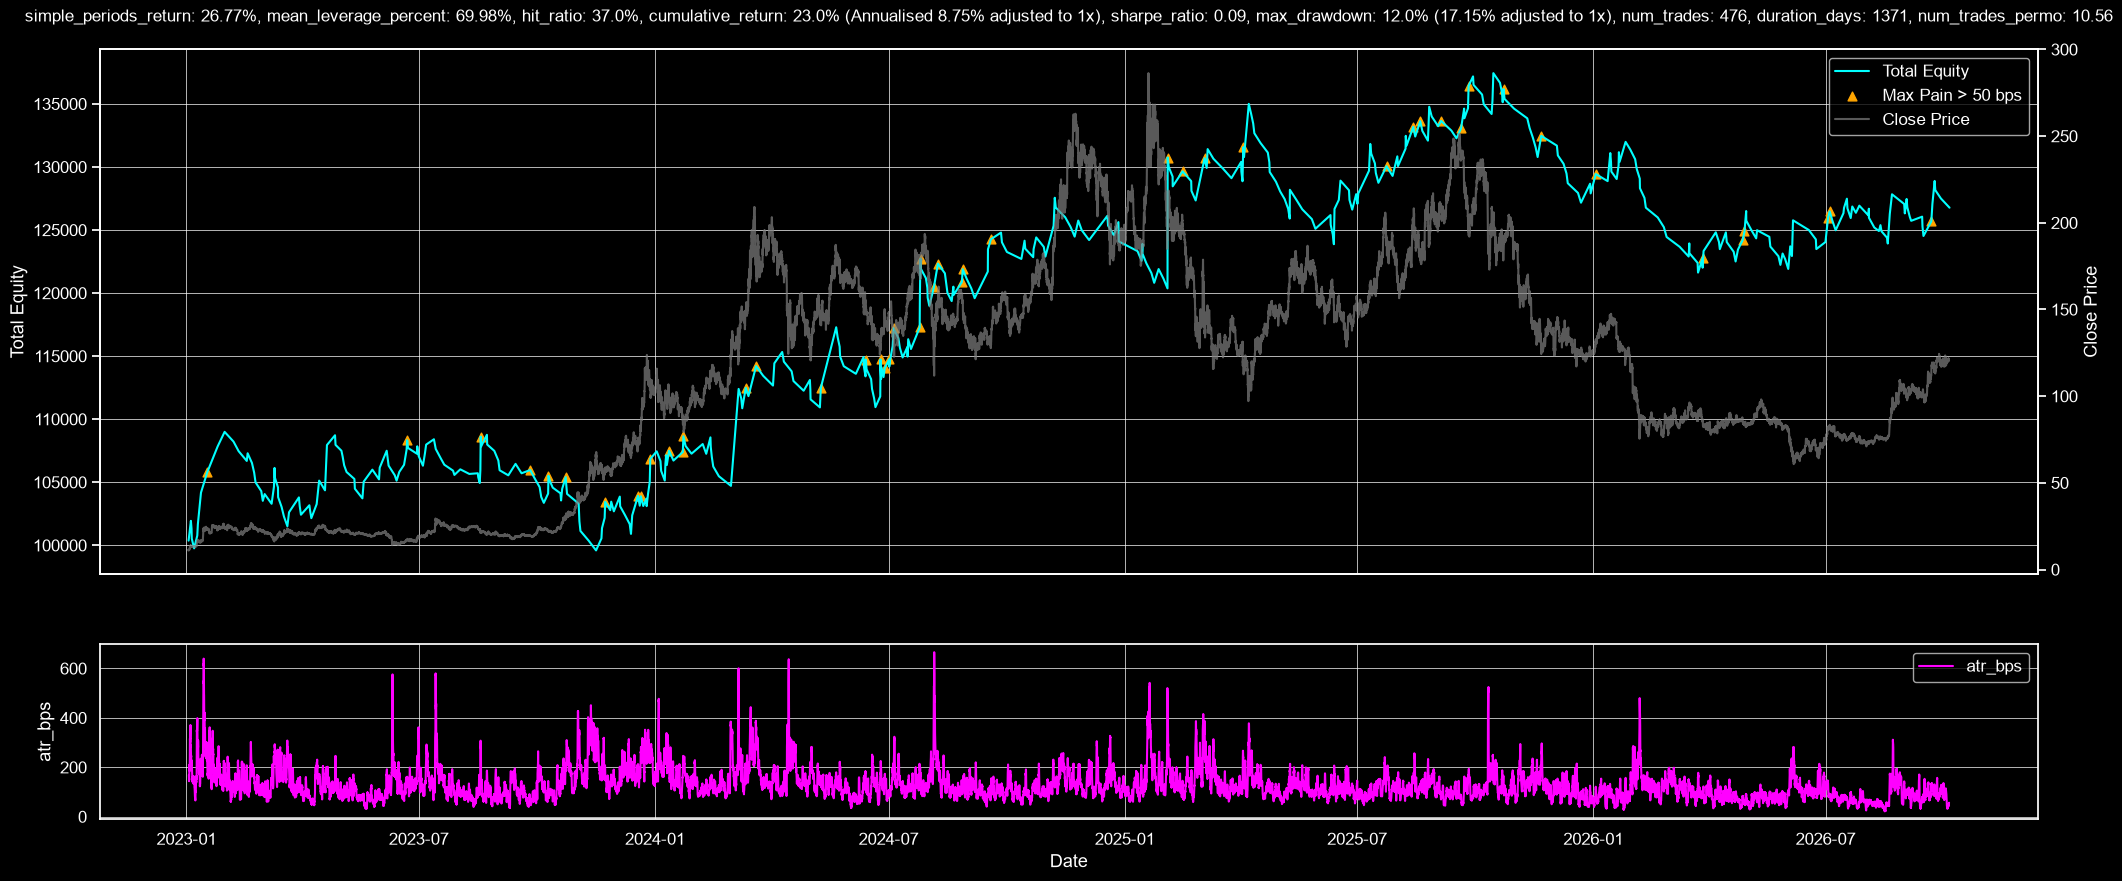

In [120]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(25, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
plt.style.use('dark_background')

ax_top.set_title(summary, fontsize=12, color='white', pad=20)
ax_top.set_ylabel('Total Equity', color='white')

ax_top.plot(pd_flattened_trades.index, pd_flattened_trades['total_equity'],
            label='Total Equity', color='cyan')

sl_mask = pd_flattened_trades['reason'] == 'SL'
maxpain_mask = (np.abs(pd_flattened_trades['max_pain_percent']) > MAXPAIN_CUTOFF_BPS/100) & (pd_flattened_trades.reason == 'TP')

# ax_top.scatter(pd_flattened_trades.index[sl_mask], pd_flattened_trades.loc[sl_mask, 'total_equity'], color='red', s=40, marker='v', label='SL')
ax_top.scatter(pd_flattened_trades.index[maxpain_mask], pd_flattened_trades.loc[maxpain_mask, 'total_equity'], color='orange', s=40, marker='^', label=f'Max Pain > {MAXPAIN_CUTOFF_BPS} bps')

ax2 = ax_top.twinx()
ax2.set_ylabel('Close Price', color='white')
ax2.grid(False)

if pd_candles_ta is not None:
    _pd_candles_ta = pd_candles_ta[(pd_candles_ta.timestamp_ms>=min_timestamp_ms) & (pd_candles_ta.timestamp_ms<=max_timestamp_ms)]

    candle_times = pd.to_datetime(_pd_candles_ta['timestamp_ms'], unit='ms')
    ax2.plot(candle_times, _pd_candles_ta['close'],
            color='gray', linewidth=1.5, alpha=0.7, label='Close Price')
    ax2.tick_params(axis='y', labelcolor='white')

    lines1, labels1 = ax_top.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax_top.legend(lines1 + lines2, labels1 + labels2, loc='best')

    ax_bottom.set_xlabel('Date', color='white')
    ax_bottom.set_ylabel('atr_bps', color='white')
    ax_bottom.plot(candle_times, _pd_candles_ta['atr_bps'],
                color='magenta', linewidth=1.5, label='atr_bps')
    ax_bottom.legend(loc='best')
    
    threshold = _pd_candles_ta['atr_bps']/np.sqrt(24) > 200 # atr converted from 1d to 1h bars equivalence
    threshold_filter = threshold.shift(1).fillna(False)
    start = threshold & ~threshold_filter
    end = ~threshold & threshold_filter
    start.iloc[0] = threshold.iloc[0]
    end.iloc[-1] = threshold.iloc[-1]
    starts = candle_times[start]
    ends = candle_times[end]
    for st, en in zip(starts, ends):
        ax_top.axvspan(st, en, alpha=0.2, color='yellow')
    
plt.show()

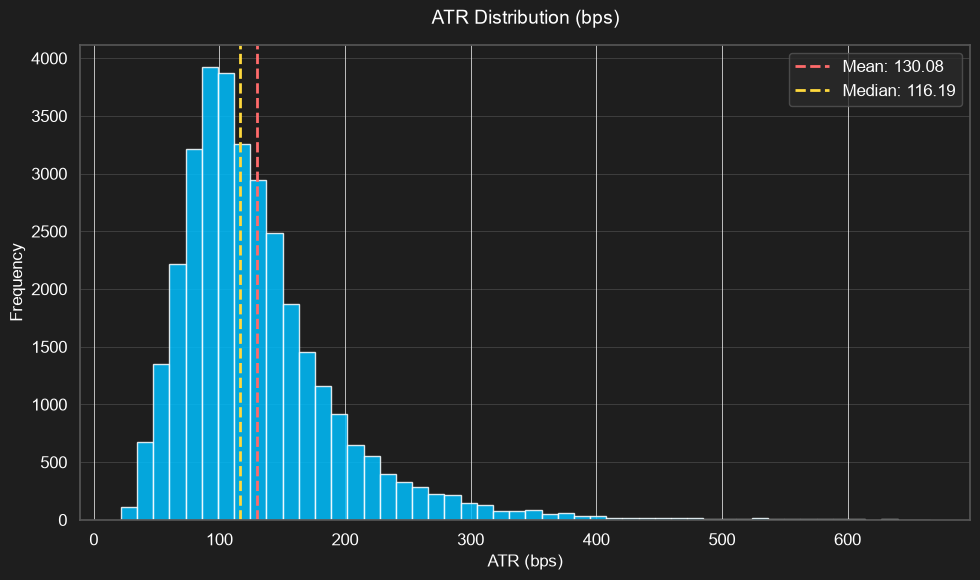

In [121]:
plt.style.use('dark_background')

fig, ax = plt.subplots(figsize=(10, 6), facecolor='#1e1e1e')
ax.set_facecolor('#1e1e1e')

n_bins = 50
counts, bins, patches = ax.hist(
    pd_candles_ta['atr_bps'].dropna(),
    bins=n_bins,
    color='#00bfff',
    edgecolor='#ffffff',
    alpha=0.85
)

mean_val = pd_candles_ta['atr_bps'].mean()
median_val = pd_candles_ta['atr_bps'].median()

ax.axvline(mean_val, color='#ff6b6b', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
ax.axvline(median_val, color='#ffd93d', linestyle='--', linewidth=2, label=f'Median: {median_val:.2f}')

ax.set_title('ATR Distribution (bps)', color='white', fontsize=14, pad=15)
ax.set_xlabel('ATR (bps)', color='white', fontsize=12)
ax.set_ylabel('Frequency', color='white', fontsize=12)

ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_color('#555555')

ax.grid(True, axis='y', alpha=0.2, color='white')
ax.legend(facecolor='#2a2a2a', edgecolor='#555555', labelcolor='white')

plt.tight_layout()
plt.show()

Pnl contribution: Longs vs Shorts

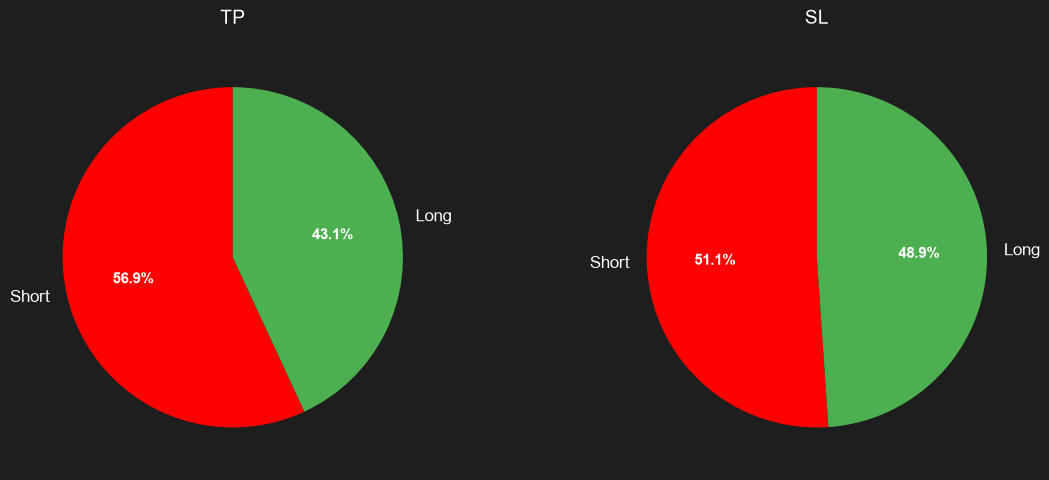

In [122]:
from datetime import datetime

_pd_flattened_trades = pd_flattened_trades
tp_data = _pd_flattened_trades[_pd_flattened_trades['reason'] == 'TP']
tp_pnl = tp_data.groupby('side')['trade_pnl_less_comm_and_slippage'].sum()

sl_data = _pd_flattened_trades[_pd_flattened_trades['reason'] == 'SL']
sl_pnl_abs = sl_data.groupby('side')['trade_pnl_less_comm_and_slippage'].apply(lambda x: abs(x).sum())

side_labels = {'sell': 'Long', 'buy': 'Short'} # if exit side 'sell', entry side 'buy

plt.style.use('dark_background')  # built‑in dark theme

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor('#1e1e1e')

# 1. TP contribution
colors = ["#FF0000", '#4CAF50']  # green for long, red for short
wedges1, texts1, autotexts1 = ax1.pie(
    tp_pnl,
    labels=tp_pnl.index.map(side_labels),
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    textprops={'color': 'white', 'fontsize': 12},
    wedgeprops={'edgecolor': 'none'}
)
ax1.set_title('TP', color='white', fontsize=14, pad=15)

# 2. SL contribution
wedges2, texts2, autotexts2 = ax2.pie(
    sl_pnl_abs,
    labels=sl_pnl_abs.index.map(side_labels),
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    textprops={'color': 'white', 'fontsize': 12},
    wedgeprops={'edgecolor': 'none'}
)
ax2.set_title('SL', color='white', fontsize=14, pad=15)

# Improve visibility of percentage text
for autotext in autotexts1 + autotexts2:
    autotext.set_color('white')
    autotext.set_fontsize(11)
    autotext.set_weight('bold')

plt.tight_layout()
plt.show()

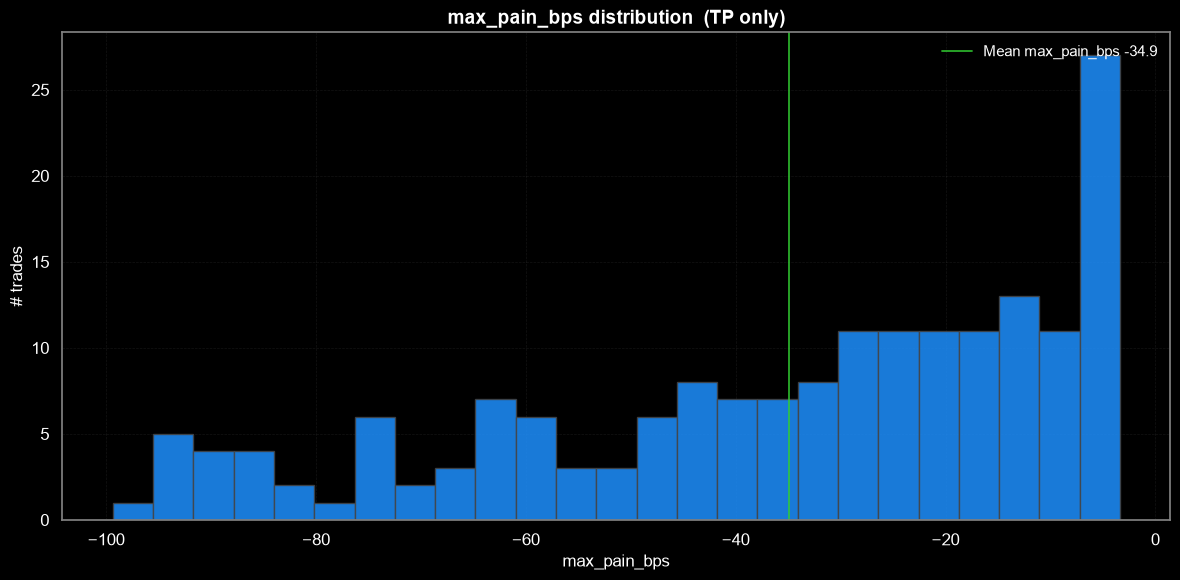

In [123]:
pd_flattened_trades['max_pain_bps'] = round(pd_flattened_trades['max_pain_percent']*100, 2)

plt.figure(figsize=(12, 6), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

plt.hist(
    pd_flattened_trades[(pd_flattened_trades.reason=='TP')]['max_pain_bps'],
    bins=25,
    edgecolor='#444444',
    alpha=0.85,
    color='dodgerblue'
)

mean_max_pain_bps = round(pd_flattened_trades[pd_flattened_trades.reason=='TP']['max_pain_bps'].mean(), 2)
plt.axvline(mean_max_pain_bps, color='limegreen', linestyle='-', linewidth=1.3, alpha=0.85,
            label=f'Mean max_pain_bps {mean_max_pain_bps}')

plt.title('max_pain_bps distribution  (TP only)', 
          fontsize=14, fontweight='bold', color='white')
plt.xlabel('max_pain_bps', fontsize=12, color='white')
plt.ylabel('# trades', fontsize=12, color='white')

plt.grid(True, alpha=0.15, linestyle='--', color='gray')
plt.legend(loc='upper right', frameon=False, fontsize=10.5, labelcolor='white')

ax.tick_params(colors='white', which='both')
ax.spines['bottom'].set_color('gray')
ax.spines['top'].set_color('gray')
ax.spines['left'].set_color('gray')
ax.spines['right'].set_color('gray')

plt.tight_layout()
plt.show()

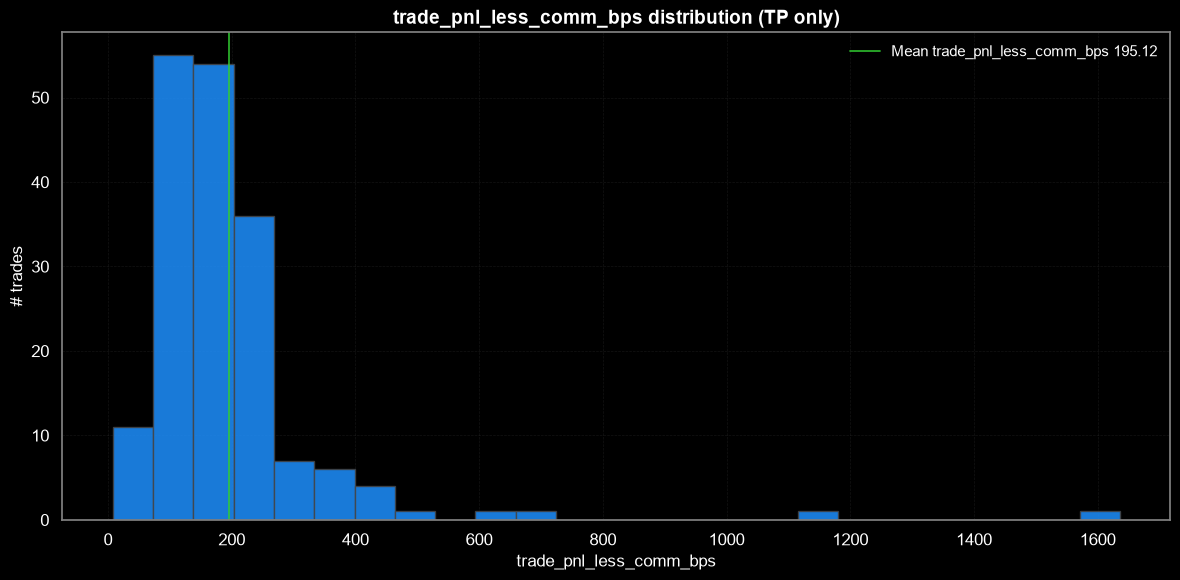

In [124]:
pd_flattened_trades['trade_pnl_less_comm_bps'] = round(pd_flattened_trades['trade_pnl_less_comm_and_slippage']/pd_flattened_trades['current_position_usdt']*10000, 2)

plt.figure(figsize=(12, 6), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

plt.hist(
    pd_flattened_trades[pd_flattened_trades.reason=='TP']['trade_pnl_less_comm_bps'],
    bins=25,
    edgecolor='#444444',
    alpha=0.85,
    color='dodgerblue'
)

mean_trade_pnl_less_comm_bps = round(pd_flattened_trades[pd_flattened_trades.reason=='TP']['trade_pnl_less_comm_bps'].mean(), 2)
plt.axvline(mean_trade_pnl_less_comm_bps, color='limegreen', linestyle='-', linewidth=1.3, alpha=0.85,
            label=f'Mean trade_pnl_less_comm_bps {mean_trade_pnl_less_comm_bps}')

plt.title('trade_pnl_less_comm_bps distribution (TP only)', 
          fontsize=14, fontweight='bold', color='white')
plt.xlabel('trade_pnl_less_comm_bps', fontsize=12, color='white')
plt.ylabel('# trades', fontsize=12, color='white')

plt.grid(True, alpha=0.15, linestyle='--', color='gray')
plt.legend(loc='upper right', frameon=False, fontsize=10.5, labelcolor='white')

ax.tick_params(colors='white', which='both')
ax.spines['bottom'].set_color('gray')
ax.spines['top'].set_color('gray')
ax.spines['left'].set_color('gray')
ax.spines['right'].set_color('gray')

plt.tight_layout()
plt.show()

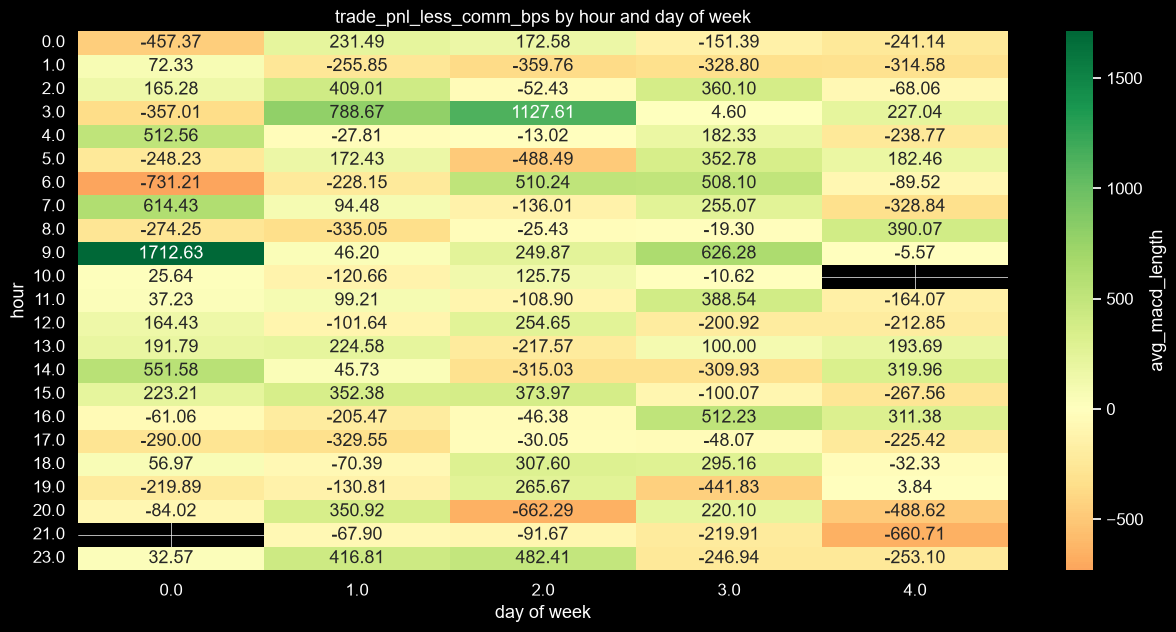

In [125]:
grouped = pd_flattened_trades[pd_flattened_trades.reason.isin(['TP','SL'])].groupby(['entry_hour', 'entry_dayofweek']).agg(
    sum_trade_pnl_less_comm_bps=('trade_pnl_less_comm_bps', 'sum'),
).reset_index()

min_sum_trade_pnl_less_comm_bps = grouped['sum_trade_pnl_less_comm_bps'].min()
max_sum_trade_pnl_less_comm_bps = grouped['sum_trade_pnl_less_comm_bps'].max()

heatmap_data = grouped.pivot(index='entry_hour', columns='entry_dayofweek', values='sum_trade_pnl_less_comm_bps')

plt.figure(figsize=(15, 7), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

sns.heatmap(
    heatmap_data, 
    annot=True, 
    fmt='.2f', 
    cmap='RdYlGn', 
    vmin=min_sum_trade_pnl_less_comm_bps,
    vmax=max_sum_trade_pnl_less_comm_bps,
    center=0,
    cbar_kws={'label': 'avg_macd_length by hour and day of week'}
)

ax.set_title('trade_pnl_less_comm_bps by hour and day of week', color='white')
ax.set_xlabel('day of week', color='white')
ax.set_ylabel('hour', color='white')
ax.tick_params(colors='white')
cbar = ax.collections[0].colorbar
cbar.set_label('avg_macd_length', color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

plt.show()

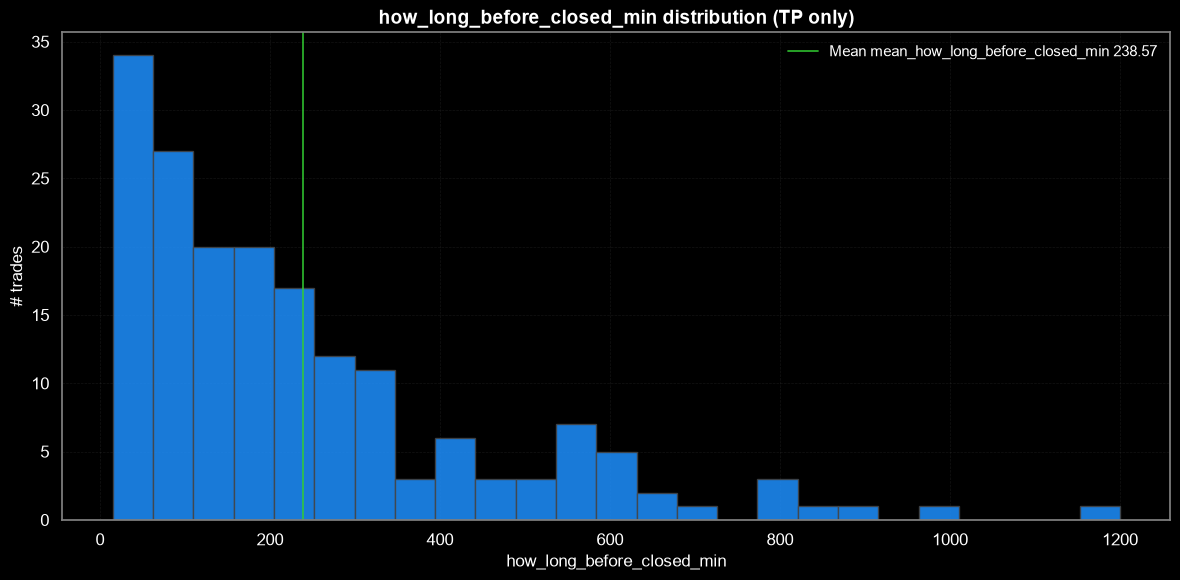

In [126]:
pd_flattened_trades['how_long_before_closed_min'] = pd_flattened_trades['how_long_before_closed_sec']/60

plt.figure(figsize=(12, 6), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

plt.hist(
    pd_flattened_trades[pd_flattened_trades.reason=='TP']['how_long_before_closed_min'],
    bins=25,
    edgecolor='#444444',
    alpha=0.85,
    color='dodgerblue'
)

mean_how_long_before_closed_min = round(pd_flattened_trades[pd_flattened_trades.reason=='TP']['how_long_before_closed_min'].mean(), 2)
plt.axvline(mean_how_long_before_closed_min, color='limegreen', linestyle='-', linewidth=1.3, alpha=0.85,
            label=f'Mean mean_how_long_before_closed_min {mean_how_long_before_closed_min}')

plt.title('how_long_before_closed_min distribution (TP only)', 
          fontsize=14, fontweight='bold', color='white')
plt.xlabel('how_long_before_closed_min', fontsize=12, color='white')
plt.ylabel('# trades', fontsize=12, color='white')

plt.grid(True, alpha=0.15, linestyle='--', color='gray')
plt.legend(loc='upper right', frameon=False, fontsize=10.5, labelcolor='white')

ax.tick_params(colors='white', which='both')
ax.spines['bottom'].set_color('gray')
ax.spines['top'].set_color('gray')
ax.spines['left'].set_color('gray')
ax.spines['right'].set_color('gray')

plt.tight_layout()
plt.show()

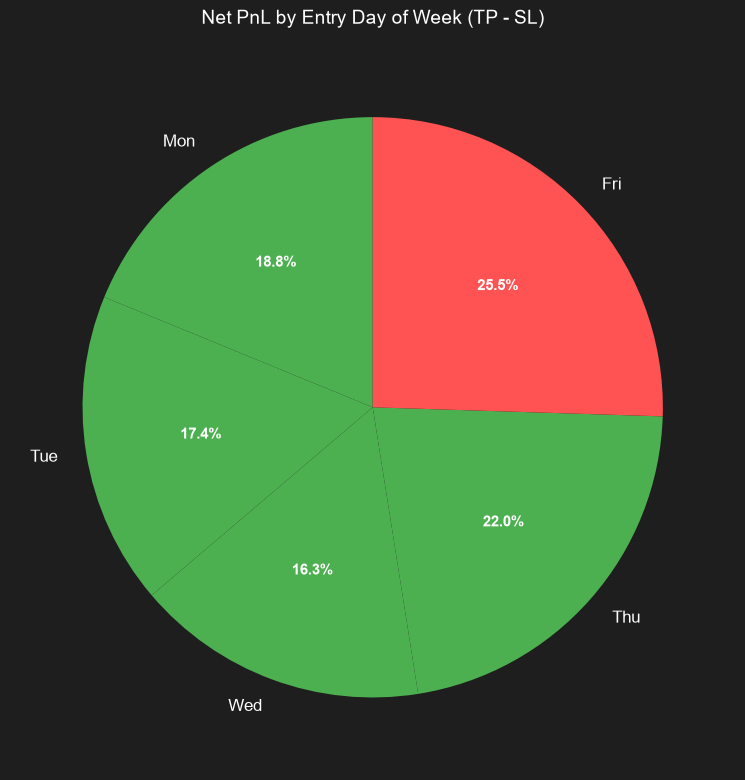

In [127]:
net_by_day = pd_flattened_trades.groupby('entry_dayofweek')['trade_pnl_less_comm'].sum()

day_names = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
labels = [day_names[d] for d in net_by_day.index]
values = net_by_day.values

abs_values = np.abs(values)
colors = ['#4CAF50' if v >= 0 else '#FF5252' for v in values]

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(8, 8))
fig.patch.set_facecolor('#1e1e1e')

wedges, texts, autotexts = ax.pie(
    abs_values,
    labels=labels,
    autopct=lambda pct: f'{pct:.1f}%',
    startangle=90,
    colors=colors,
    textprops={'color': 'white', 'fontsize': 12},
    wedgeprops={'edgecolor': 'none'}
)

ax.set_title('Net PnL by Entry Day of Week (TP - SL)', color='white', fontsize=14, pad=15)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(11)
    autotext.set_weight('bold')

plt.tight_layout()
plt.show()


Parameter       Value
--------------  -------
Risk-Free Rate  3.5%
Periods/Year    252
Compounded      Yes
Match Dates     Yes


                           Strategy
-------------------------  ----------
Start Period               2023-01-02
End Period                 2026-10-05
Risk-Free Rate             3.5%
Time in Market             29.0%

Cumulative Return          23.31%
CAGR﹪                     3.92%

Sharpe                     0.09
Prob. Sharpe Ratio         39.91%
Smart Sharpe               0.09
Sortino                    0.19
Smart Sortino              0.18
Sortino/√2                 0.13
Smart Sortino/√2           0.13
Omega                      1.03

Max Drawdown               -11.6%
Max DD Date                2026-03-23
Max DD Period Start        2025-10-20
Max DD Period End          2026-10-05
Longest DD Days            394
Volatility (ann.)          9.46%
Calmar                     0.34
Skew                       4.69
Kurtosis                   45.19
Ulcer Performance I

None

,Start,Valley,End,Days,Max Drawdown,99% Max Drawdown
1,2025-10-20,2026-03-23,2026-10-05,351,-11.603393,-11.438674
2,2023-02-06,2023-11-16,2024-03-05,394,-8.906388,-8.198153
3,2025-04-09,2025-06-12,2025-09-24,169,-8.285553,-7.139623
4,2024-05-22,2024-06-20,2024-07-24,64,-5.420169,-4.827038
5,2024-11-08,2025-01-23,2025-02-02,87,-5.314087,-5.070518


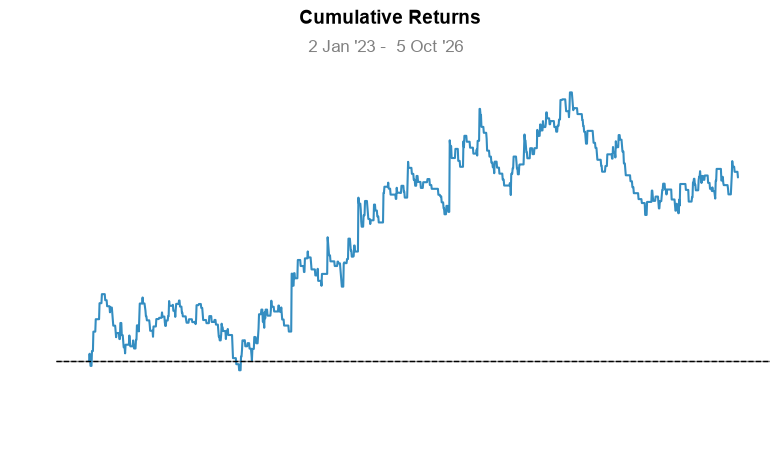

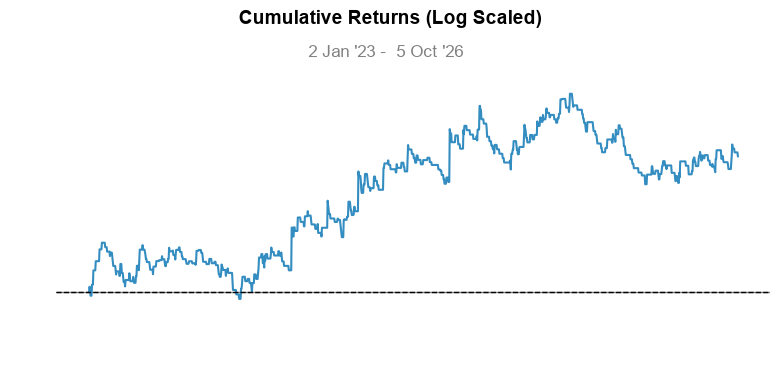

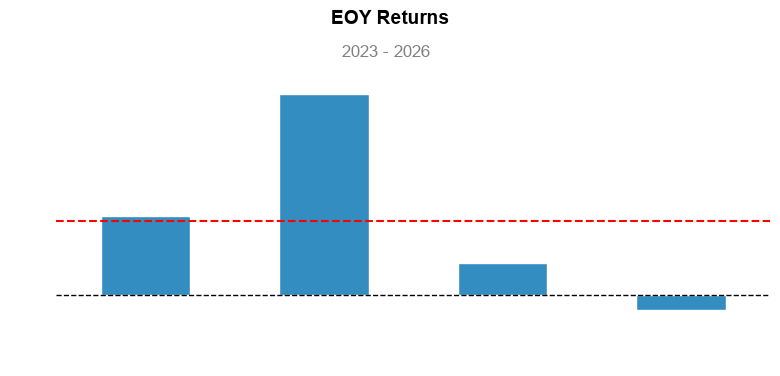

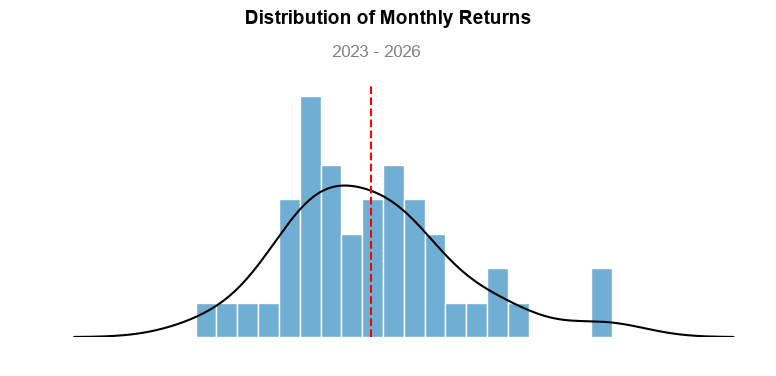

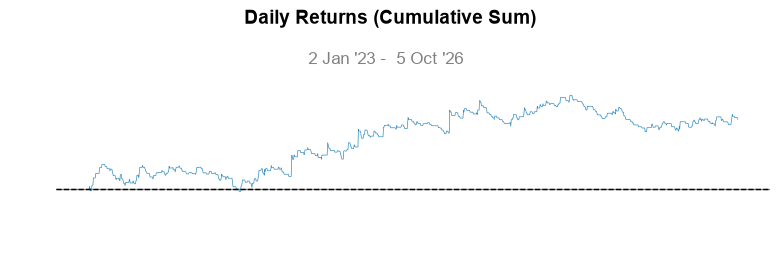

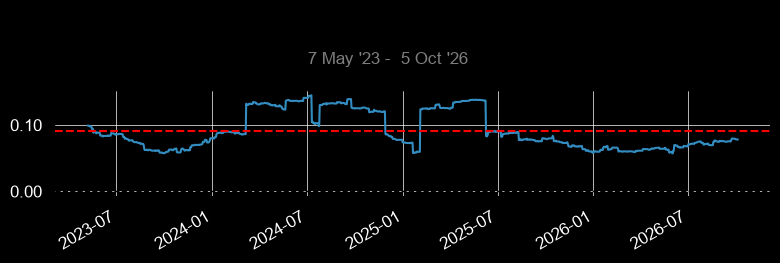

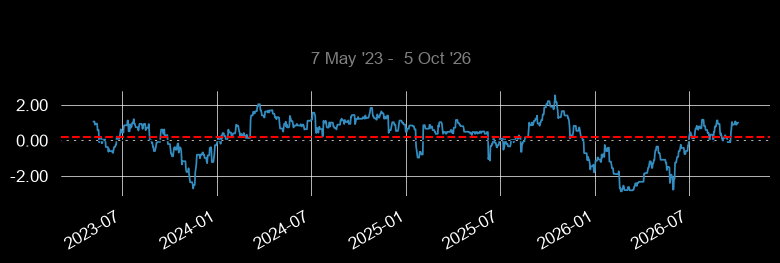

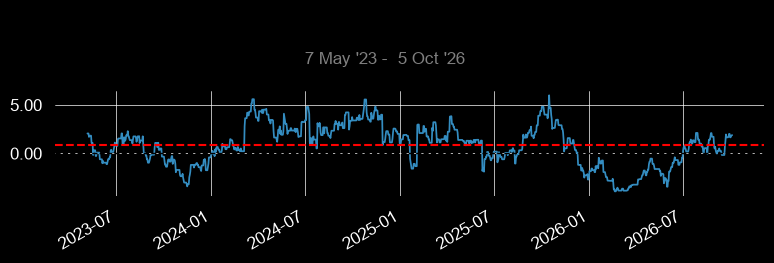

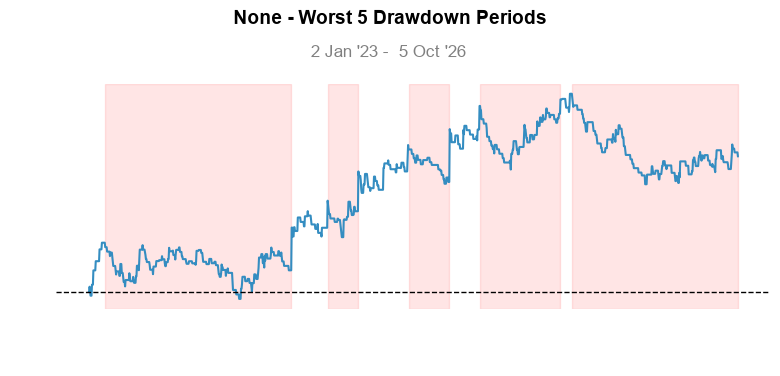

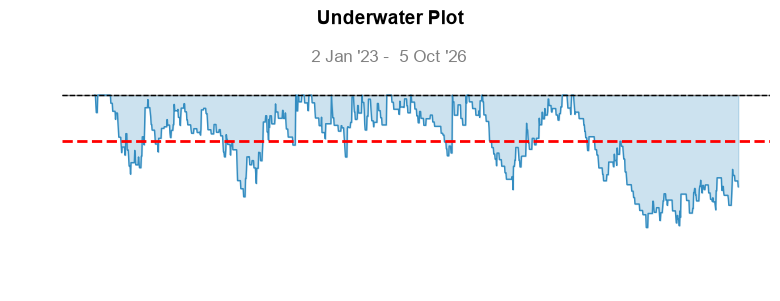

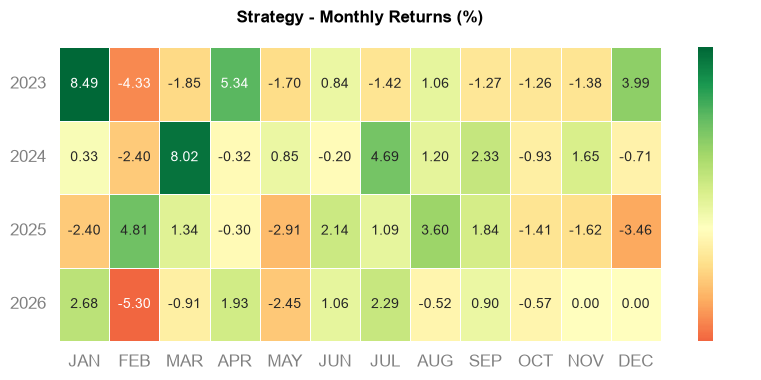

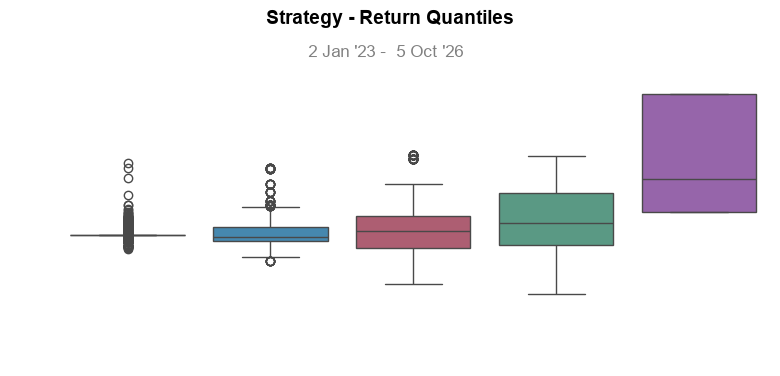

In [128]:
qs.reports.full(
    returns=resampled_returns, 
    rf=RISK_FREE_RATE,
    title="Tear Sheet"
    )